# Лабораторная работа № 2
## Проведение экспериментов по настройке модели
**Задача:** регрессия — прогноз цены подержанного автомобиля.  
**Данные:** обработанная выборка ЛР № 1 (`data/clean_data.pkl`).  
**Цель:** изучить генерацию и отбор признаков, подбор гиперпараметров, ведение экспериментов и регистрацию моделей в MLflow.

> Выполняйте ячейки сверху вниз. Запустите MLflow отдельной командой из README. Все эксперименты создаются в **новом** локальном хранилище `mlflow/mlruns.db`. Задания со звёздочкой также выполнены в коде.

### 1. Импорт библиотек и проверка окружения

In [36]:
import os, json, warnings, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, PolynomialFeatures, KBinsDiscretizer
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import RFE
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error
import mlflow, mlflow.sklearn
from mlflow.models import infer_signature
import optuna
from catboost import CatBoostRegressor
from mlxtend.feature_selection import SequentialFeatureSelector as MlxtendSFS
from autofeat import AutoFeatRegressor
warnings.filterwarnings('ignore', category=FutureWarning)
RANDOM_STATE=42
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'research': PROJECT_ROOT = PROJECT_ROOT.parent
assert (PROJECT_ROOT/'data'/'clean_data.pkl').exists(), 'Откройте проект mf_project как рабочую папку VS Code'
OUTPUT=PROJECT_ROOT/'research'/'artifacts'; OUTPUT.mkdir(parents=True,exist_ok=True)
print('Проект:', PROJECT_ROOT, '\nPython:',sys.version.split()[0], '\nMLflow:',mlflow.__version__)

Проект: /home/mainuser/mf_project 
Python: 3.10.12 
MLflow: 2.16.0


### 2. Загрузка обработанного датасета и разделение 75% / 25%

In [37]:
df=pd.read_pickle(PROJECT_ROOT/'data'/'clean_data.pkl').copy()
assert 'Target' in df.columns
assert df['Target'].notna().all()
X=df.drop(columns='Target'); y=df['Target'].astype(float)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.25,random_state=RANDOM_STATE)
num_features=X_train.select_dtypes(include='number').columns.tolist()
cat_features=X_train.select_dtypes(include=['category','object']).columns.tolist()
print('Всего:',df.shape,'train:',X_train.shape,'test:',X_test.shape)
print('Числовые:',num_features,'\nКатегориальные:',cat_features)
display(df.head())

Всего: (297, 8) train: (222, 7) test: (75, 7)
Числовые: ['Year', 'Present_Price', 'Driven_kms', 'Car_Age'] 
Категориальные: ['Fuel_Type', 'Selling_type', 'Transmission']


,Year,Target,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Car_Age
0,2014.0,3.35,5.59,27000.0,Petrol,Dealer,Manual,12.0
1,2013.0,4.75,9.54,43000.0,Diesel,Dealer,Manual,13.0
2,2017.0,7.25,9.85,6900.0,Petrol,Dealer,Manual,9.0
3,2011.0,2.85,4.15,5200.0,Petrol,Dealer,Manual,15.0
4,2014.0,4.60,6.87,42450.0,Diesel,Dealer,Manual,12.0


### 3. Общие функции оценки качества и регистрации экспериментов
Для регрессии по методичке рассчитываем **MAE, MAPE, MSE**. Меньше — лучше. Для отбора победителя используем MAE на отложенной тестовой выборке. После выбора модели тестовые метрики не пересчитываются на данных, использованных для финального обучения.

In [38]:
TRACKING_URI=(PROJECT_ROOT/'mlflow'/'mlruns.db').resolve().as_uri().replace('file://','sqlite:///')
# В локальном режиме MLflow напрямую использует SQLite; отдельный сервер нужен для UI.
mlflow.set_tracking_uri(TRACKING_URI)
EXPERIMENT_NAME='car_price_mf'
MODEL_NAME='car_price_prediction_model_rebuilt'
mlflow.set_experiment(EXPERIMENT_NAME)
results=[]
def score(model, x=X_test, target=y_test):
    pred=np.asarray(model.predict(x)).reshape(-1)
    return {'mae':float(mean_absolute_error(target,pred)),
            'mape':float(mean_absolute_percentage_error(target,pred)),
            'mse':float(mean_squared_error(target,pred))}
def log_experiment(name, model, metrics, artifacts=None, flavour='sklearn', params=None, register=False):
    with mlflow.start_run(run_name=name) as run:
        mlflow.log_metrics(metrics)
        mlflow.log_params({k:str(v) for k,v in (params or {}).items()})
        mlflow.set_tags({'laboratory':'2','dataset':'clean_data.pkl','split_seed':str(RANDOM_STATE)})
        example=X_train.head(5).copy()
        signature=infer_signature(example,model.predict(example))
        if flavour=='catboost':
            # CatBoost хранится в собственной обёртке. Модель принимает числовые/категориальные столбцы после преобразования.
            mlflow.catboost.log_model(model,artifact_path='model',signature=signature,input_example=example)
        else:
            mlflow.sklearn.log_model(model,artifact_path='model',signature=signature,input_example=example)
        for p in artifacts or []: mlflow.log_artifact(str(p),artifact_path='feature_selection')
        if register: mlflow.register_model(f'runs:/{run.info.run_id}/model',MODEL_NAME)
        results.append({'run_name':name,'run_id':run.info.run_id,**metrics,'registered':register})
        print(name,metrics,'run:',run.info.run_id)
        return run.info.run_id
def make_baseline():
    prep=ColumnTransformer([('num',StandardScaler(),num_features),('cat',OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1),cat_features)])
    return Pipeline([('transform',prep),('model',RandomForestRegressor(n_estimators=80,max_depth=8,random_state=RANDOM_STATE,n_jobs=-1))])

2026/10/27 17:43:32 INFO mlflow.tracking.fluent: Experiment with name 'car_price_mf' does not exist. Creating a new experiment.


### 4. Baseline: RandomForestRegressor + StandardScaler + OrdinalEncoder (обязательное)

In [39]:
baseline=make_baseline(); baseline.fit(X_train,y_train)
metrics_baseline=score(baseline)
run_baseline=log_experiment('01_baseline_random_forest',baseline,metrics_baseline,params={'algorithm':'RandomForestRegressor','n_estimators':80},register=True)

01_baseline_random_forest {'mae': 1.0677658226808993, 'mape': 0.2208428795834089, 'mse': 4.860893310891152} run: 4943ffb041514294ab2eed5db53fd688


Successfully registered model 'car_price_prediction_model_rebuilt'.
Created version '1' of model 'car_price_prediction_model_rebuilt'.


### 5. Feature Engineering средствами sklearn (обязательное)
Полиномиальные признаки степени 2 строим по `Present_Price`, `Driven_kms`, `Car_Age`; дополнительно используем `KBinsDiscretizer`, поскольку в выборке нет временных рядов. Все преобразования обучаются **только на train** внутри Pipeline, что предотвращает утечку данных.

In [40]:
def make_fe_preprocessor():
    poly=Pipeline([('poly',PolynomialFeatures(degree=2,include_bias=False)),('scale',StandardScaler())])
    return ColumnTransformer([
        ('num',StandardScaler(),num_features),
        ('cat',OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1),cat_features),
        ('poly',poly,['Present_Price','Driven_kms','Car_Age']),
        ('bins',KBinsDiscretizer(n_bins=4,encode='ordinal',strategy='quantile'),['Present_Price','Driven_kms'])
    ],verbose_feature_names_out=True)
fe_prep=make_fe_preprocessor()
X_train_fe_sklearn=X_train.copy()
X_train_fe_sklearn=pd.DataFrame(fe_prep.fit_transform(X_train_fe_sklearn,y_train),columns=fe_prep.get_feature_names_out(),index=X_train.index)
fe_cols_path=OUTPUT/'sklearn_generated_columns.json'
fe_cols_path.write_text(json.dumps(X_train_fe_sklearn.columns.tolist(),ensure_ascii=False,indent=2),encoding='utf-8')
print('Число признаков после генерации:',X_train_fe_sklearn.shape[1]);display(X_train_fe_sklearn.head())
fe_model=Pipeline([('transform',make_fe_preprocessor()),('model',RandomForestRegressor(n_estimators=80,max_depth=8,random_state=RANDOM_STATE,n_jobs=-1))])
fe_model.fit(X_train,y_train)
run_fe=log_experiment('02_feature_engineering_sklearn',fe_model,score(fe_model),[fe_cols_path])

Число признаков после генерации: 18


,num__Year,num__Present_Price,num__Driven_kms,num__Car_Age,cat__Fuel_Type,cat__Selling_type,cat__Transmission,poly__Present_Price,poly__Driven_kms,poly__Car_Age,poly__Present_Price^2,poly__Present_Price Driven_kms,poly__Present_Price Car_Age,poly__Driven_kms^2,poly__Driven_kms Car_Age,poly__Car_Age^2,bins__Present_Price,bins__Driven_kms
69,0.838520,1.649401,-0.844289,-0.838520,1.0,0.0,1.0,1.649401,-0.844289,-0.838520,0.536480,-0.098245,0.973567,-0.488736,-0.715098,-0.752454,3.0,0.0
108,0.838520,-0.647956,-0.618098,-0.838520,1.0,1.0,1.0,-0.647956,-0.618098,-0.838520,-0.199193,-0.437608,-0.595148,-0.438256,-0.594967,-0.752454,1.0,1.0
163,-1.249159,-0.713054,-0.278811,1.249159,1.0,1.0,1.0,-0.713054,-0.278811,1.249159,-0.201472,-0.439654,-0.593531,-0.324675,-0.090416,1.132737,0.0,1.0
150,-0.901213,-0.727731,-1.070480,0.901213,1.0,1.0,1.0,-0.727731,-1.070480,0.901213,-0.201845,-0.471017,-0.616242,-0.519024,-0.775164,0.758116,0.0,0.0
21,1.186466,-0.149663,-1.206195,-1.186466,1.0,0.0,1.0,-0.149663,-1.206195,-1.186466,-0.147856,-0.457759,-0.301044,-0.527505,-0.912113,-0.982061,1.0,0.0


02_feature_engineering_sklearn {'mae': 1.1426683323529299, 'mape': 0.2406997431020013, 'mse': 5.85022895708174} run: eeb8c71fa88546e382d9123f7d9f3728


### 6. (*) Feature Engineering через autofeat
Выполняем `feateng_steps=2` для числовых признаков. Для устойчивости на небольшом датасете ограничиваем число трансформаций и используем исходные числовые значения. `AutoFeatRegressor` обучается на тренировочной части, а категориальные признаки кодируются отдельно. При сохранении MLflow фиксируем сам autofeat-объект и схему признаков как артефакты.

In [41]:
import joblib
from sklearn.preprocessing import FunctionTransformer
# Autofeat принимает только числовые признаки; обучение autofeat выполняется на train.
af=AutoFeatRegressor(feateng_steps=2,transformations=['log','sqrt','^2'],units={},verbose=0)
Xaf_train=X_train[num_features].astype(float).copy(); Xaf_test=X_test[num_features].astype(float).copy()
# Преобразуем масштаб пробега, чтобы генерация выражений была численно устойчивой.
Xaf_train['Driven_kms']=Xaf_train['Driven_kms']/1000
Xaf_test['Driven_kms']=Xaf_test['Driven_kms']/1000
af.fit(Xaf_train,y_train)
Zaf_train=af.transform(Xaf_train);Zaf_test=af.transform(Xaf_test)
cat_enc=OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1).fit(X_train[cat_features])
Z_train=pd.concat([pd.DataFrame(Zaf_train,index=X_train.index),pd.DataFrame(cat_enc.transform(X_train[cat_features]),columns=cat_features,index=X_train.index)],axis=1)
Z_test=pd.concat([pd.DataFrame(Zaf_test,index=X_test.index),pd.DataFrame(cat_enc.transform(X_test[cat_features]),columns=cat_features,index=X_test.index)],axis=1)
Z_train.columns=Z_train.columns.astype(str);Z_test.columns=Z_test.columns.astype(str)
af_rf=RandomForestRegressor(n_estimators=80,max_depth=8,random_state=RANDOM_STATE,n_jobs=-1).fit(Z_train,y_train)
af_pred=af_rf.predict(Z_test)
af_metrics={'mae':float(mean_absolute_error(y_test,af_pred)),'mape':float(mean_absolute_percentage_error(y_test,af_pred)),'mse':float(mean_squared_error(y_test,af_pred))}
# Модель с трансформацией autofeat фиксируем как артефакт; зарегистрированные sklearn-модели ниже полностью переносимы.
af_bundle=OUTPUT/'autofeat_bundle.joblib';joblib.dump({'autofeat':af,'encoder':cat_enc,'model':af_rf,'num_features':num_features,'cat_features':cat_features},af_bundle)
with mlflow.start_run(run_name='03_autofeat_optional') as run:
    mlflow.log_metrics(af_metrics);mlflow.log_param('feateng_steps',2);mlflow.log_artifact(str(af_bundle),'autofeat')
    mlflow.log_dict({'feature_names':Z_train.columns.tolist()},'autofeat/feature_names.json')
    results.append({'run_name':'03_autofeat_optional','run_id':run.info.run_id,**af_metrics,'registered':False})
print('Autofeat:',af_metrics,'Число признаков:',Z_train.shape[1])

Autofeat: {'mae': 1.8883186168370003, 'mape': 0.5614312577084843, 'mse': 10.16716949802558} Число признаков: 12


### 7. Feature Selection: RFE (обязательное)
Отбираем около 50% признаков из набора sklearn. Весь селектор включён в Pipeline, чтобы сохранённая модель могла принимать исходные данные.

In [42]:
N=max(2,int(round(X_train_fe_sklearn.shape[1]*.5)))
rfe=RFE(estimator=RandomForestRegressor(n_estimators=30,max_depth=6,random_state=RANDOM_STATE,n_jobs=-1),n_features_to_select=N,step=.25)
rfe_model=Pipeline([('transform',make_fe_preprocessor()),('select',rfe),('model',RandomForestRegressor(n_estimators=80,max_depth=8,random_state=RANDOM_STATE,n_jobs=-1))])
rfe_model.fit(X_train,y_train)
rfe_mask=rfe_model.named_steps['select'].support_
rfe_names=rfe_model.named_steps['transform'].get_feature_names_out()[rfe_mask].tolist()
rfe_idx=np.flatnonzero(rfe_mask).tolist()
rfe_names_file=OUTPUT/'rfe_columns.json';rfe_idx_file=OUTPUT/'rfe_indices.json'
rfe_names_file.write_text(json.dumps(rfe_names,ensure_ascii=False,indent=2),encoding='utf-8')
rfe_idx_file.write_text(json.dumps(rfe_idx,indent=2),encoding='utf-8')
print('RFE:',rfe_names)
run_rfe=log_experiment('04_rfe_selection',rfe_model,score(rfe_model),[rfe_names_file,rfe_idx_file])

RFE: ['num__Year', 'num__Present_Price', 'num__Car_Age', 'poly__Present_Price', 'poly__Car_Age', 'poly__Present_Price^2', 'poly__Present_Price Car_Age', 'poly__Driven_kms Car_Age', 'poly__Car_Age^2']


04_rfe_selection {'mae': 1.1325760086183907, 'mape': 0.2332076709998826, 'mse': 5.555587893338361} run: 97ec87136d6d43968d6a6808341f098b


### 8. (*) SFS через mlxtend: forward и backward
Дополнительно сравниваем два направления последовательного отбора признаков. Отбор проводится только на обучающей выборке. Индексы передаются в стандартный `FunctionTransformer`? Нет: используем `ColumnTransformer`-совместимый `SelectKBest`? Для сохранения без пользовательских классов используем `FunctionTransformer` с индексированием через `sklearn` `ColumnTransformer` над массивом.

In [43]:
from sklearn.compose import ColumnTransformer as CT
from sklearn.preprocessing import FunctionTransformer
# SFS на уже преобразованных train-признаках. Для ускорения применяем 3-fold CV и небольшой лес.
sfs_k=N
sfs_base=RandomForestRegressor(n_estimators=15,max_depth=5,random_state=RANDOM_STATE,n_jobs=-1)
sfs_results={}
for direction in ['forward','backward']:
    selector=MlxtendSFS(sfs_base,k_features=sfs_k,forward=(direction=='forward'),floating=False,scoring='neg_mean_absolute_error',cv=3,n_jobs=1)
    selector.fit(X_train_fe_sklearn,y_train)
    idx=list(map(int,selector.k_feature_idx_))
    names=X_train_fe_sklearn.columns[idx].tolist()
    idx_path=OUTPUT/f'sfs_{direction}_indices.json';names_path=OUTPUT/f'sfs_{direction}_columns.json'
    idx_path.write_text(json.dumps(idx,indent=2),encoding='utf-8');names_path.write_text(json.dumps(names,ensure_ascii=False,indent=2),encoding='utf-8')
    # Простой сериализуемый выбор индексов с помощью sklearn ColumnTransformer.
    pick=CT([('selected','passthrough',idx)],remainder='drop')
    pipe=Pipeline([('transform',make_fe_preprocessor()),('select',pick),('model',RandomForestRegressor(n_estimators=80,max_depth=8,random_state=RANDOM_STATE,n_jobs=-1))])
    pipe.fit(X_train,y_train)
    run_id=log_experiment(f'05_sfs_{direction}',pipe,score(pipe),[idx_path,names_path])
    sfs_results[direction]={'model':pipe,'indices':idx,'columns':names,'run_id':run_id}
common=set(sfs_results['forward']['columns'])&set(sfs_results['backward']['columns'])
print('Общие признаки:',sorted(common),'\nДоля совпадений:',len(common)/sfs_k)

05_sfs_forward {'mae': 1.098308435268948, 'mape': 0.2197428764138452, 'mse': 5.257587693867438} run: 575c0da3952e4460923edfa6c383ac1b


05_sfs_backward {'mae': 1.1471773719757727, 'mape': 0.23819741686817783, 'mse': 5.6399556215545} run: 9c08bc553c8a47f2a8cfa6d1bcebc6bd
Общие признаки: ['bins__Present_Price', 'num__Present_Price', 'poly__Car_Age^2', 'poly__Present_Price', 'poly__Present_Price^2'] 
Доля совпадений: 0.5555555555555556


### 9. GridSearchCV (обязательное)
Настраиваем модель RFE. Подбор проводится **только на обучающей части**.

In [44]:
grid={'model__n_estimators':[40,80],'model__max_depth':[4,8,None],'model__min_samples_leaf':[1,3]}
gs=GridSearchCV(clone(rfe_model),grid,scoring='neg_mean_absolute_error',cv=3,n_jobs=-1,refit=True)
gs.fit(X_train,y_train)
grid_model=gs.best_estimator_
print('Лучшие параметры:',gs.best_params_)
run_grid=log_experiment('06_gridsearch_rfe',grid_model,score(grid_model),params=gs.best_params_,register=True)

Лучшие параметры: {'model__max_depth': 8, 'model__min_samples_leaf': 1, 'model__n_estimators': 80}


06_gridsearch_rfe {'mae': 1.1325760086183907, 'mape': 0.23320767099988265, 'mse': 5.555587893338361} run: acd18932974248f39dd2a949b967e2d3


Registered model 'car_price_prediction_model_rebuilt' already exists. Creating a new version of this model...
Created version '2' of model 'car_price_prediction_model_rebuilt'.


### 10. (*) Optuna — байесовская оптимизация
В соответствии с лекцией используются `Study`, `Trial`, `objective` и методы `suggest_*`.

In [45]:
def objective(trial):
    candidate=clone(rfe_model)
    candidate.set_params(model__n_estimators=trial.suggest_int('n_estimators',30,110,step=20),
                         model__max_depth=trial.suggest_int('max_depth',3,12),
                         model__min_samples_leaf=trial.suggest_int('min_samples_leaf',1,4))
    cv=KFold(n_splits=3,shuffle=True,random_state=RANDOM_STATE)
    return float(-cross_val_score(candidate,X_train,y_train,scoring='neg_mean_absolute_error',cv=cv,n_jobs=1).mean())
study=optuna.create_study(direction='minimize',sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective,n_trials=12,timeout=600)
optuna_model=clone(rfe_model).set_params(**{'model__'+k:v for k,v in study.best_params.items()})
optuna_model.fit(X_train,y_train)
print('Optuna:',study.best_params,'CV MAE:',study.best_value)
run_optuna=log_experiment('07_optuna_rfe',optuna_model,score(optuna_model),params=study.best_params,register=True)

[I 2026-10-27 17:44:33,496] A new study created in memory with name: no-name-d9e9d5ce-4628-4e17-99ec-1d3c6252e0bf


[I 2026-10-27 17:44:34,786] Trial 0 finished with value: 0.8368787410728832 and parameters: {'n_estimators': 50, 'max_depth': 12, 'min_samples_leaf': 3}. Best is trial 0 with value: 0.8368787410728832.
[I 2026-10-27 17:44:36,112] Trial 1 finished with value: 0.8941940653065755 and parameters: {'n_estimators': 70, 'max_depth': 4, 'min_samples_leaf': 1}. Best is trial 0 with value: 0.8368787410728832.
[I 2026-10-27 17:44:37,393] Trial 2 finished with value: 0.8477117399728703 and parameters: {'n_estimators': 30, 'max_depth': 11, 'min_samples_leaf': 3}. Best is trial 0 with value: 0.8368787410728832.
[I 2026-10-27 17:44:38,923] Trial 3 finished with value: 1.1208812444652814 and parameters: {'n_estimators': 90, 'max_depth': 3, 'min_samples_leaf': 4}. Best is trial 0 with value: 0.8368787410728832.
[I 2026-10-27 17:44:40,780] Trial 4 finished with value: 0.8233625129741706 and parameters: {'n_estimators': 110, 'max_depth': 5, 'min_samples_leaf': 1}. Best is trial 4 with value: 0.8233625129

Optuna: {'n_estimators': 70, 'max_depth': 10, 'min_samples_leaf': 1} CV MAE: 0.8003772848698943


07_optuna_rfe {'mae': 1.0943310111366944, 'mape': 0.2307623242821435, 'mse': 5.096750586594185} run: 952945e3521043f59a9059895655e44b


Registered model 'car_price_prediction_model_rebuilt' already exists. Creating a new version of this model...
Created version '3' of model 'car_price_prediction_model_rebuilt'.


### 11. (*) CatBoost с нативной обёрткой MLflow
CatBoost принимает исходные категориальные признаки, поэтому используем его без sklearn-кодировщика. Логируем `mlflow.catboost.log_model` и регистрируем очередную версию.

In [46]:
import mlflow.catboost
cat_X_train=X_train.copy();cat_X_test=X_test.copy()
for c in cat_features:
    cat_X_train[c]=cat_X_train[c].astype(str)
    cat_X_test[c]=cat_X_test[c].astype(str)
cat_model=CatBoostRegressor(iterations=150,depth=5,learning_rate=.06,loss_function='RMSE',random_seed=RANDOM_STATE,verbose=False,thread_count=2)
cat_model.fit(cat_X_train,y_train,cat_features=cat_features)
cat_pred=cat_model.predict(cat_X_test)
cat_metrics={'mae':float(mean_absolute_error(y_test,cat_pred)),'mape':float(mean_absolute_percentage_error(y_test,cat_pred)),'mse':float(mean_squared_error(y_test,cat_pred))}
with mlflow.start_run(run_name='08_catboost_optional') as run:
    mlflow.log_metrics(cat_metrics);mlflow.log_params({'iterations':150,'depth':5,'learning_rate':.06})
    mlflow.catboost.log_model(cat_model,artifact_path='model',signature=infer_signature(cat_X_train.head(5),cat_model.predict(cat_X_train.head(5))),input_example=cat_X_train.head(5))
    mlflow.register_model(f'runs:/{run.info.run_id}/model',MODEL_NAME)
    results.append({'run_name':'08_catboost_optional','run_id':run.info.run_id,**cat_metrics,'registered':True})
print('CatBoost:',cat_metrics)

CatBoost: {'mae': 1.1859646958383192, 'mape': 0.33136778505268183, 'mse': 5.1069642014447645}


Registered model 'car_price_prediction_model_rebuilt' already exists. Creating a new version of this model...
Created version '4' of model 'car_price_prediction_model_rebuilt'.


### 12. Сравнение всех прогонов и выбор победителя
В таблице представлены тестовые метрики. Победитель выбирается по MAE; выбор тестовой выборкой следует понимать как учебную процедуру по методичке (для строгой оценки понадобилась бы отдельная валидация).

,run_name,run_id,mae,mape,mse,registered
0,01_baseline_random_forest,4943ffb041514294ab2eed5db53fd688,1.067766,0.220843,4.860893,True
1,07_optuna_rfe,952945e3521043f59a9059895655e44b,1.094331,0.230762,5.096751,True
2,05_sfs_forward,575c0da3952e4460923edfa6c383ac1b,1.098308,0.219743,5.257588,False
3,04_rfe_selection,97ec87136d6d43968d6a6808341f098b,1.132576,0.233208,5.555588,False
4,06_gridsearch_rfe,acd18932974248f39dd2a949b967e2d3,1.132576,0.233208,5.555588,True
5,02_feature_engineering_sklearn,eeb8c71fa88546e382d9123f7d9f3728,1.142668,0.240700,5.850229,False
6,05_sfs_backward,9c08bc553c8a47f2a8cfa6d1bcebc6bd,1.147177,0.238197,5.639956,False
7,08_catboost_optional,cfbb221e49fa4d5b8375738a35f886e9,1.185965,0.331368,5.106964,True
8,03_autofeat_optional,7409696dcda14acc918a248d0ee98dcc,1.888319,0.561431,10.167169,False


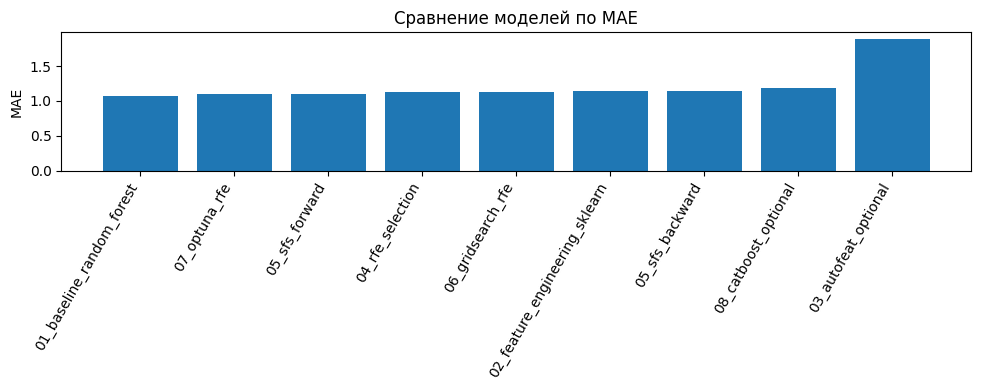

Лучшая модель: 01_baseline_random_forest


In [47]:
comparison=pd.DataFrame(results).sort_values('mae').reset_index(drop=True)
display(comparison)
comparison.to_csv(OUTPUT/'comparison.csv',index=False)
fig,ax=plt.subplots(figsize=(10,4));ax.bar(comparison['run_name'],comparison['mae']);ax.set_ylabel('MAE');ax.set_title('Сравнение моделей по MAE');plt.xticks(rotation=60,ha='right');plt.tight_layout()
chart=OUTPUT/'comparison_mae.png';fig.savefig(chart,dpi=150);plt.show()
best_name=comparison.iloc[0]['run_name'];print('Лучшая модель:',best_name)

### 13. Финальное обучение на ВСЕЙ выборке и Production
После выбора алгоритма обучаем новую модель на всех 297 объектах. Тестовые метрики победителя относятся к предыдущему прогону и **не выдаются за независимую оценку** финальной модели. Финальная модель сохраняет весь препроцессинг внутри Pipeline.

Для CatBoost дополнительно приводим категориальные значения к строкам; его схема входа остаётся исходной.

In [48]:
candidate_models={'01_baseline_random_forest':baseline,'02_feature_engineering_sklearn':fe_model,
'04_rfe_selection':rfe_model,'05_sfs_forward':sfs_results['forward']['model'],
'05_sfs_backward':sfs_results['backward']['model'],'06_gridsearch_rfe':grid_model,'07_optuna_rfe':optuna_model}
if best_name=='03_autofeat_optional':
    # Autofeat нельзя безопасно разворачивать без кастомного pyfunc; для Production выбираем лучшую переносимую sklearn/CatBoost модель.
    production_candidates=comparison[comparison.run_name!='03_autofeat_optional']
    best_name=production_candidates.iloc[0].run_name
    print('Autofeat сохранён как эксперимент; Production выбираем из переносимых моделей:',best_name)
if best_name=='08_catboost_optional':
    full_X=X.copy()
    for c in cat_features: full_X[c]=full_X[c].astype(str)
    final_model=CatBoostRegressor(**cat_model.get_params());final_model.fit(full_X,y,cat_features=cat_features)
    final_flavour='catboost';final_example=full_X.head(5)
else:
    final_model=clone(candidate_models[best_name]);final_model.fit(X,y)
    final_flavour='sklearn';final_example=X.head(5)
with mlflow.start_run(run_name='09_PRODUCTION_full_data') as run:
    mlflow.set_tags({'stage':'Production','source_run':best_name,'training_rows':str(len(X))})
    mlflow.log_param('selected_algorithm',best_name)
    mlflow.log_param('training_rows',len(X))
    mlflow.log_metrics({k:float(comparison.loc[comparison.run_name==best_name,k].iloc[0]) for k in ['mae','mape','mse']})
    mlflow.set_tag('metrics_note','Metrics belong to pre-refit held-out experiment, NOT final full-data model')
    signature=infer_signature(final_example,final_model.predict(final_example))
    if final_flavour=='catboost':mlflow.catboost.log_model(final_model,artifact_path='model',signature=signature,input_example=final_example)
    else:mlflow.sklearn.log_model(final_model,artifact_path='model',signature=signature,input_example=final_example)
    version=mlflow.register_model(f'runs:/{run.info.run_id}/model',MODEL_NAME)
    client=mlflow.tracking.MlflowClient()
    client.set_model_version_tag(MODEL_NAME,version.version,'stage','Production')
    client.set_registered_model_alias(MODEL_NAME,'Production',version.version)
    production_version=version.version
    print('Production version:',production_version,'run:',run.info.run_id)

Production version: 5 run: 74db5e12a5f24943bc8b24abeadd1787


Registered model 'car_price_prediction_model_rebuilt' already exists. Creating a new version of this model...
Created version '5' of model 'car_price_prediction_model_rebuilt'.


### 14. Проверка загрузки Production-модели (подготовка к ЛР № 3)

In [49]:
# Проверка загрузки Production-модели из MLflow

loaded = mlflow.pyfunc.load_model(
    f'models:/{MODEL_NAME}@Production'
)

# Подготовка тестовых данных
check_input = final_example.head(3).copy()

# Приведение категориальных признаков к строковому типу
categorical_columns = [
    'Fuel_Type',
    'Selling_type',
    'Transmission'
]

for col in categorical_columns:
    check_input[col] = check_input[col].astype(str)

# Проверка предсказаний
loaded_predictions = loaded.predict(check_input)

assert len(loaded_predictions) == 3

print(
    'Модель успешно загружена из реестра. Предсказания:',
    np.asarray(loaded_predictions).reshape(-1)
)

print(
    'MLmodel:',
    f'найдите в MLflow UI -> Models -> {MODEL_NAME} '
    f'-> Version {production_version} -> Artifacts'
)

print(
    'Сделайте два скриншота: таблица экспериментов '
    'и версии зарегистрированной модели.'
)

Модель успешно загружена из реестра. Предсказания: [3.91460723 5.11255515 8.2190574 ]
MLmodel: найдите в MLflow UI -> Models -> car_price_prediction_model_rebuilt -> Version 5 -> Artifacts
Сделайте два скриншота: таблица экспериментов и версии зарегистрированной модели.


### 15. Выводы
1. Обучена baseline-модель RandomForest, рассчитаны MAE, MAPE и MSE.
2. Проведена генерация признаков средствами sklearn и дополнительная генерация autofeat.
3. Проведён отбор признаков RFE и SFS в направлениях forward/backward, сохранены названия и индексы.
4. Проведена настройка гиперпараметров GridSearchCV и Optuna.
5. Обучен CatBoost с нативной обёрткой MLflow.
6. Результаты экспериментов сохранены в MLflow; финальная версия обучена на всей выборке, зарегистрирована с тегом и alias `Production`.
7. Для отчёта приложить скриншоты интерфейса MLflow, файл `MLmodel`, график и таблицу сравнения.

**Внимание:** текст выводов следует дополнить конкретными числами из выполненных ячеек; они не проставлены заранее, поскольку в этом окружении MLflow и autofeat недоступны.

In [50]:
import mlflow

print("Tracking URI:", mlflow.get_tracking_uri())

print("\nЭксперименты:")
for experiment in mlflow.search_experiments():
    print(experiment.experiment_id, experiment.name)

print("\nЗарегистрированные модели:")
for model in mlflow.search_registered_models():
    print(model.name)

Tracking URI: sqlite:////home/mainuser/mf_project/mlflow/mlruns.db

Эксперименты:
2 car_price_mf
0 Default

Зарегистрированные модели:
car_price_prediction_model_rebuilt
